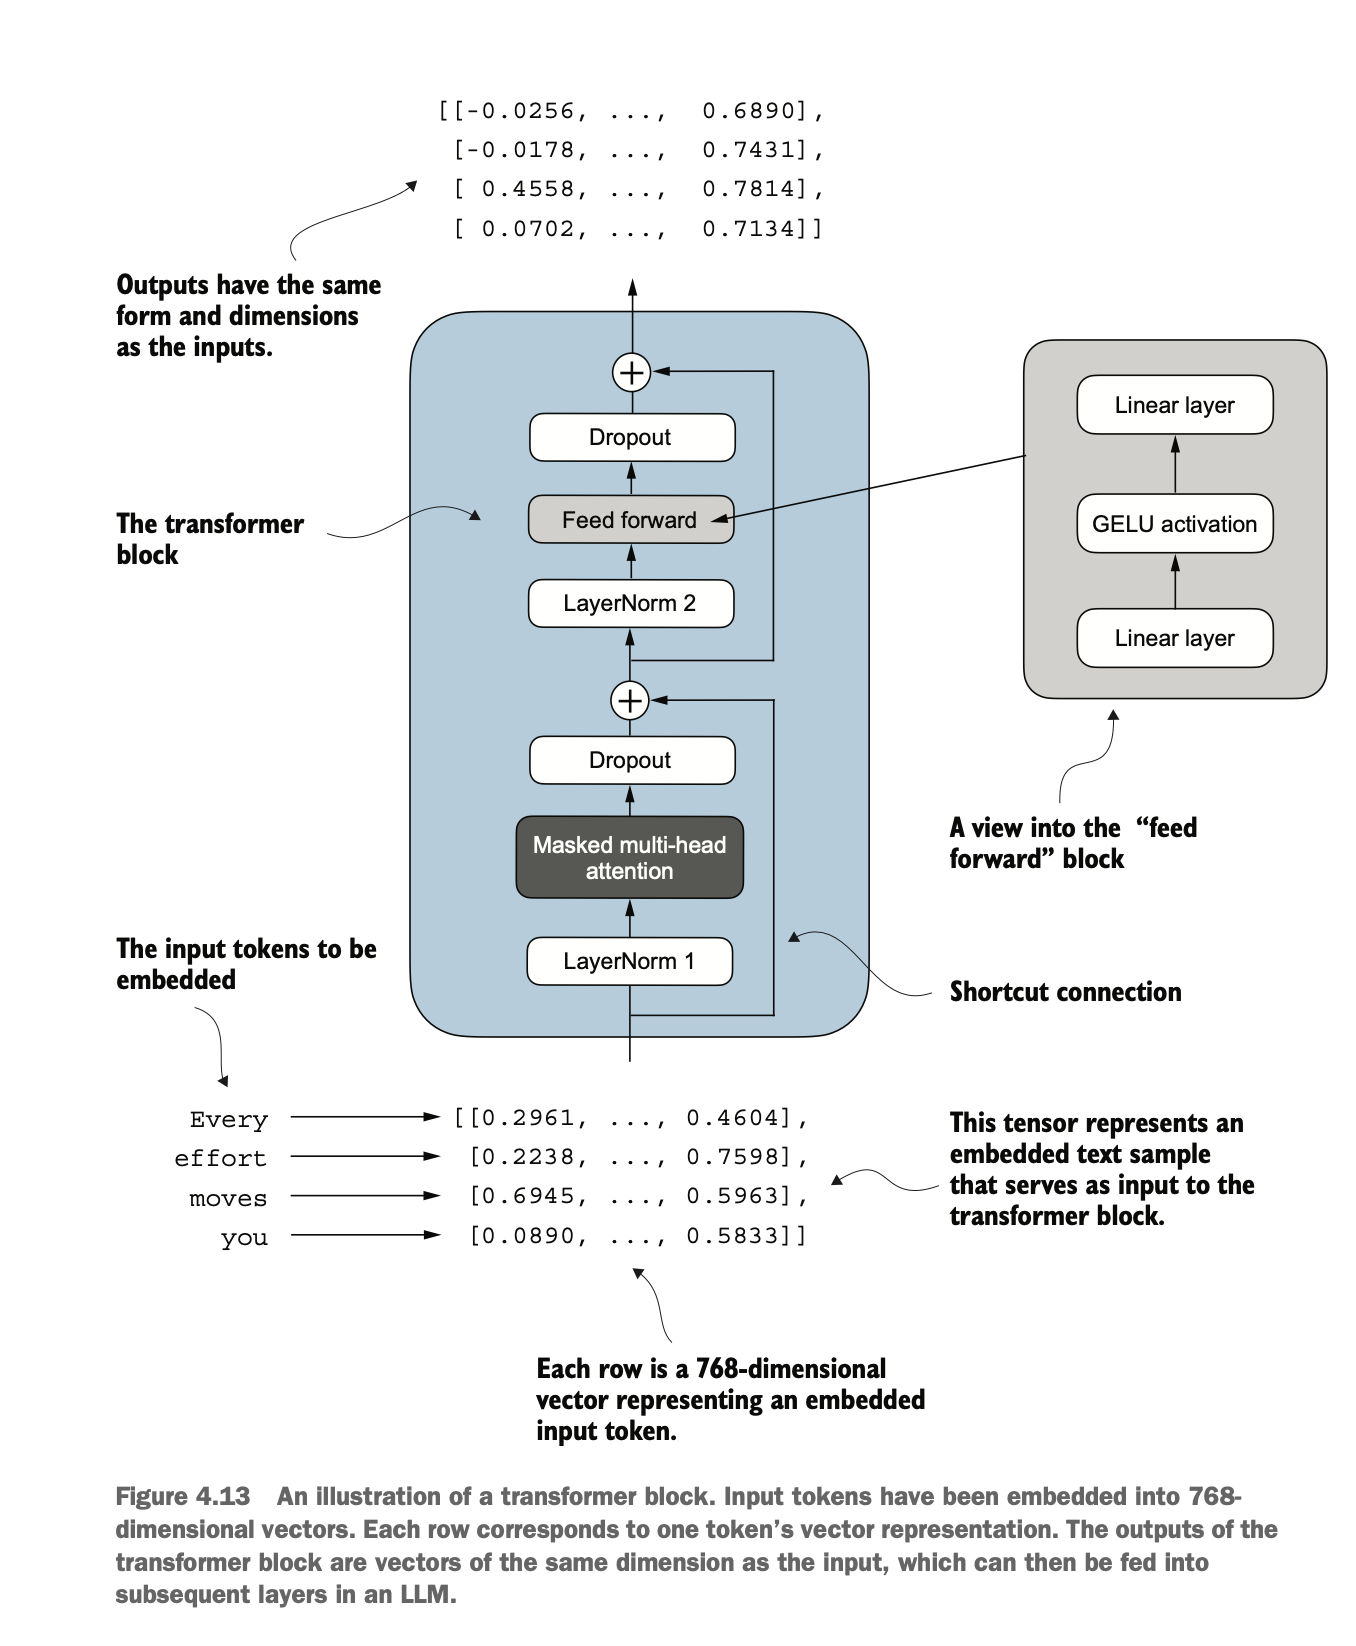


In [ ]:
try:
    from notebook_setup import FeedForward, GPT_CONFIG_124M, MultiHeadAttention
except ModuleNotFoundError:
    from CH04_Implementing_a_GPT_model_from_scratch_to_generate_text.notebook_setup import (
        FeedForward,
        GPT_CONFIG_124M,
        MultiHeadAttention,
        LayerNorm,
    )
import torch.nn as nn
import torch


class TransformerBlock(nn.Module):

    def __init__(self, cfg):
        super().__init__()

        self.att = MultiHeadAttention(
            #
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"],
        )

        self.ff = FeedForward(cfg)
        self.norm1 = nn.LayerNorm(cfg["emb_dim"])
        self.norm2 = nn.LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        shortcut = x  # Shortcut connection for feed forward block
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Adds the original input back

        return x


# Using the GPT_CONFIG_124M dictionary we defined earlier,
# let’s instantiate a transformer block and feed it some sample data:


torch.manual_seed(123)
x = torch.rand(
    2, 4, 768
)  # Creates sample input of shape [batch_size, num_tokens, emb_dim]
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("\nInput shape:", x.shape)
print("Output shape:", output.shape)


Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


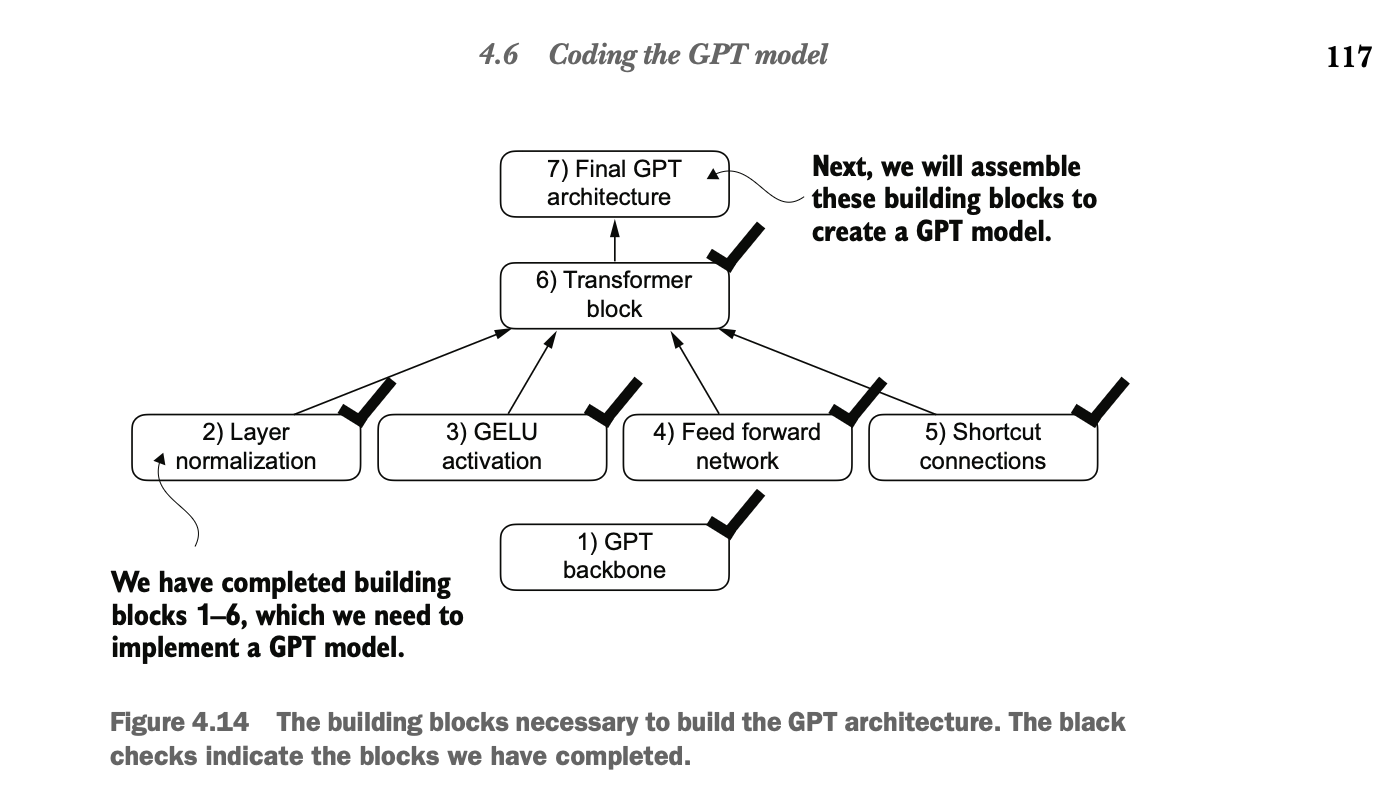
